# Ring analysis around charcoal kilns: example

This notebook shows how to use the two scripts:

- `kiln_ring_analysis.py`: samples a raster along radial transects around every kiln and computes a mean and median per distance ring.
- `plot_kiln_rings.py`: draws the three-panel figure from the results.

Both are used the same way: you pass a dict with the parameters you want to change, and everything you leave out falls back to the `DEFAULTS` at the top of each file.

## 1. Setup

Save this notebook in the same folder as the two `.py` files. If it lives somewhere else, uncomment the `sys.path` line and put in the folder that contains the scripts.

`autoreload` makes the notebook pick up changes to the `.py` files without restarting the kernel.

In [1]:
%load_ext autoreload
%autoreload 2

from kiln_ring_analysis_function import kiln_ring_analysis, DEFAULTS as ANALYSIS_DEFAULTS
from plot_kiln_rings_function import plot_kiln_rings, DEFAULTS as PLOT_DEFAULTS

## 2. Available parameters

These are all the keys you can put in the parameter dict, with their default values. Any other key raises an error, so typos are caught.

In [2]:
ANALYSIS_DEFAULTS

{'gpkg': 'kohlmeiler_2056.gpkg',
 'id_column': 'ID_PAROLINI',
 'tif': 'merged_dem.tif',
 'band': 1,
 'rings': [(0, 6), (6, 12), (12, 18), (18, 24)],
 'n_rays': 16,
 'step': 1,
 'weighted': False,
 'include_centre': False,
 'min_valid': 0.9,
 'summary_of': 'mean',
 'out_dir': '.',
 'out_prefix': None,
 'save': True,
 'verbose': True}

In [3]:
PLOT_DEFAULTS

{'rings_csv': 'merged_dem_rings.csv',
 'value': 'mean',
 'y_label': 'Canopy height (m)',
 'color': '#2f6db3',
 'out_png': None,
 'save': True,
 'dpi': 200,
 'figsize': (16, 5.2),
 'show': True,
 'seed': 0}

| Key | Meaning |
|---|---|
| `gpkg` | GeoPackage with the kiln points |
| `id_column` | Column that identifies each kiln |
| `tif` | Raster to analyse |
| `band` | Band number of the raster |
| `rings` | List of `(inner, outer)` distances in metres, from inside to outside |
| `n_rays` | Number of directions, evenly spread over 360° |
| `step` | Spacing of samples along each ray, in metres |
| `weighted` | `True`: weight samples by distance (area mean); `False`: all samples count equally |
| `include_centre` | Whether the value at the kiln itself is part of the first ring |
| `min_valid` | A ring is left empty if less than this share of its samples has data |
| `summary_of` | Per-kiln value used in the overview: `"mean"` or `"median"` |
| `out_dir` | Folder for the output files |
| `out_prefix` | File name prefix (`None` = raster name) |
| `save` | Write the output files |
| `verbose` | Print the overview |

File paths are relative to the folder this notebook is in.

## 3. Run the analysis

Only list what you want to change from the defaults.

In [12]:
params = {
    "gpkg": "kohlmeiler_2056.gpkg",
    "tif": "merged_dem.tif",
    "rings": [(0, 2), (2, 4), (4, 6), (6, 8)],
    "n_rays": 16,
    "step": 1,
    "weighted": True,
    "out_dir": "results",
}

out = kiln_ring_analysis(params)

Raster:        merged_dem.tif
Band:          1 of 1 (no name)
CRS:           EPSG:2056
Pixel size:    1.0 x 1.0 m
Nodata value:  -999999.0
Kilns:         80 from kohlmeiler_2056.gpkg
Rays:          16 (every 22.5°), sample every 1 m up to 8 m
Weighted:      True
Centre used:   False
Samples per ring (identical for every kiln):
       0-2     m: 32 samples
       2-4     m: 32 samples
       4-6     m: 32 samples
       6-8     m: 32 samples

Overview across all kilns (each kiln = one ring mean, weighted):
        0-2 m  2-4 m  4-6 m  6-8 m
count   79.00  79.00  79.00  79.00
median   6.84   5.93   6.41   6.20
mean     6.96   6.71   6.51   6.43
std      4.62   4.04   3.73   3.48
min      0.00   0.00   0.00   0.00
25%      3.86   4.47   4.08   4.35
50%      6.84   5.93   6.41   6.20
75%      9.43   8.96   8.59   8.40
max     21.95  19.82  19.16  17.06

Rings left empty (too little valid data):
   mean_0_2: kilns [12]
   mean_2_4: kilns [12]
   mean_4_6: kilns [12]
   mean_6_8: kilns [12]


## 4. Look at the results

`out` is a dict:

- `out["summary"]`: overview across all kilns, one column per ring
- `out["rings"]`: one row per kiln with mean, median, number of samples and valid share per ring
- `out["samples"]`: every single sample (kiln, ray, distance, ring, value, ...)
- `out["files"]`: paths of the written files
- `out["params"]`: the full parameter set that was used

In [13]:
out["summary"].round(2)

,0-2 m,2-4 m,4-6 m,6-8 m
count,79.00,79.00,79.00,79.00
median,6.84,5.93,6.41,6.20
mean,6.96,6.71,6.51,6.43
std,4.62,4.04,3.73,3.48
min,0.00,0.00,0.00,0.00
25%,3.86,4.47,4.08,4.35
50%,6.84,5.93,6.41,6.20
75%,9.43,8.96,8.59,8.40
max,21.95,19.82,19.16,17.06


In [14]:
out["rings"].head()

,x,y,mean_0_2,median_0_2,n_0_2,valid_0_2,mean_2_4,median_2_4,n_2_4,valid_2_4,mean_4_6,median_4_6,n_4_6,valid_4_6,mean_6_8,median_6_8,n_6_8,valid_6_8
kiln_id,,,,,,,,,,,,,,,,,,
1,2.808165e+06,1.171932e+06,7.321042,7.0,32,1.0,8.483125,7.14,32,1.0,10.611818,8.17,32,1.00000,9.725208,7.7,32,1.00000
2,2.808257e+06,1.171884e+06,0.000000,0.0,32,1.0,0.000000,0.00,32,1.0,0.003068,0.00,32,1.00000,0.000333,0.0,32,1.00000
3,2.808341e+06,1.171832e+06,0.000000,0.0,32,1.0,0.000000,0.00,32,1.0,0.000000,0.00,32,0.96875,0.000000,0.0,32,0.96875
4,2.808323e+06,1.171930e+06,0.000000,0.0,32,1.0,0.000000,0.00,32,1.0,0.000000,0.00,32,1.00000,0.000000,0.0,32,0.96875
5,2.808301e+06,1.172105e+06,0.000000,0.0,32,1.0,0.000000,0.00,32,1.0,0.000000,0.00,32,1.00000,0.000000,0.0,32,1.00000


In [15]:
out["samples"].head()

,kiln_id,kiln_x,kiln_y,ray,bearing,distance,ring,ring_index,x,y,value,valid,weight
0,1,2.808165e+06,1.171932e+06,0,0.0,1.0,0-2,0,2.808165e+06,1.171933e+06,9.82,True,1.0
1,1,2.808165e+06,1.171932e+06,0,0.0,2.0,0-2,0,2.808165e+06,1.171934e+06,7.00,True,2.0
2,1,2.808165e+06,1.171932e+06,0,0.0,3.0,2-4,1,2.808165e+06,1.171935e+06,2.14,True,3.0
3,1,2.808165e+06,1.171932e+06,0,0.0,4.0,2-4,1,2.808165e+06,1.171936e+06,2.18,True,4.0
4,1,2.808165e+06,1.171932e+06,0,0.0,5.0,4-6,2,2.808165e+06,1.171937e+06,4.71,True,5.0


In [16]:
out["files"]

{'rings': PosixPath('results/merged_dem_rings.csv'),
 'summary': PosixPath('results/merged_dem_summary.csv'),
 'samples_csv': PosixPath('results/merged_dem_samples.csv'),
 'samples_gpkg': PosixPath('results/merged_dem_samples.gpkg')}

## 5. Plot

Pass the path of the `_rings.csv` file that the analysis wrote. Assign the result to a variable (`fig = ...`) so the figure is not shown twice.

80 kilns, rings: 0-2 m, 2-4 m, 4-6 m, 6-8 m
Kilns with at least one empty ring: 1
Saved results/merged_dem_rings_mean_plot.png


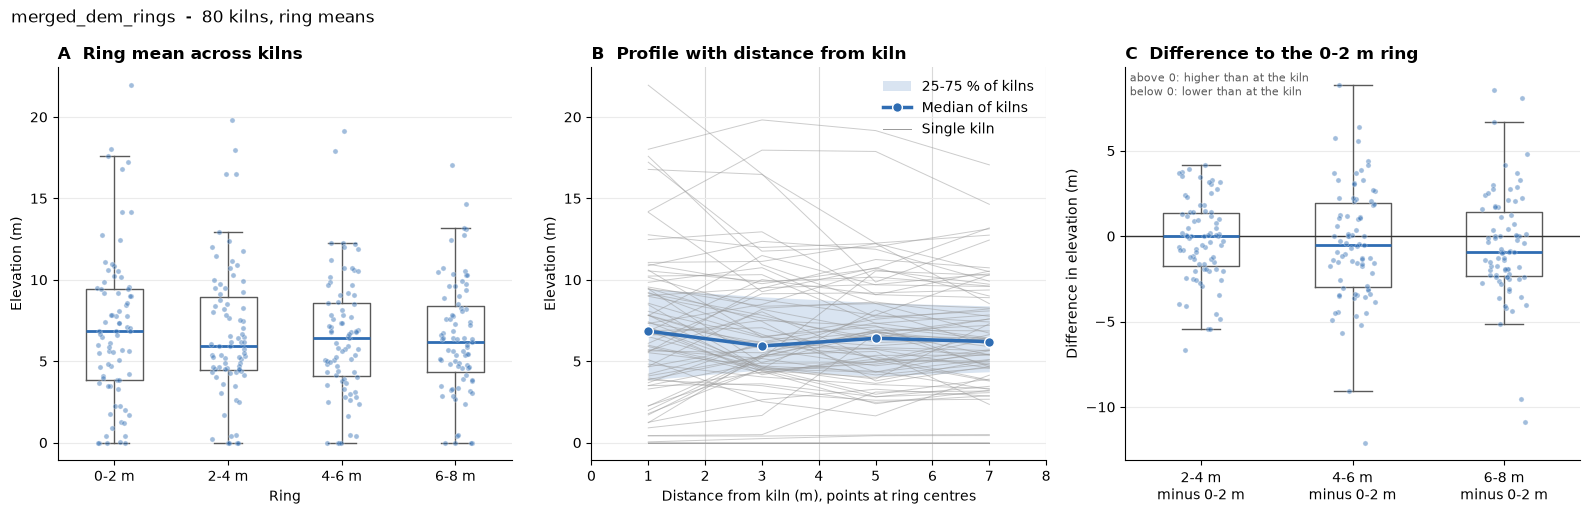

In [17]:
fig = plot_kiln_rings({
    "rings_csv": out["files"]["rings"],
    "value": "mean",
    "y_label": "Elevation (m)",
})

## 6. Several rasters in a loop

`{**params, "tif": tif}` copies the parameters from above and swaps only the raster. Outputs are named after each raster, so nothing is overwritten. Replace the file names and y-axis labels with your own.

80 kilns, rings: 0-2 m, 2-4 m, 4-6 m, 6-8 m
Kilns with at least one empty ring: 1
Saved results/merged_dem_rings_mean_plot.png


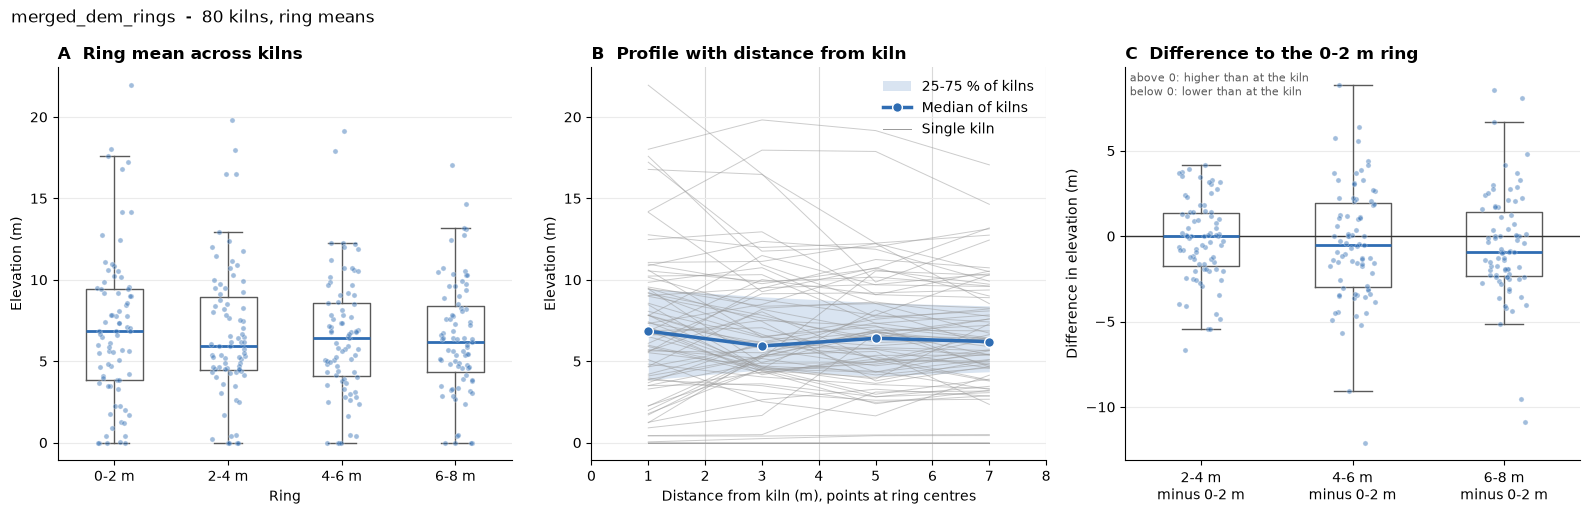

In [18]:
rasters = {
    "merged_dem.tif": "Elevation (m)",
    # "canopy_height.tif": "Canopy height (m)",
}

results = {}
for tif, y_label in rasters.items():
    results[tif] = kiln_ring_analysis({**params, "tif": tif, "verbose": False})
    fig = plot_kiln_rings({"rings_csv": results[tif]["files"]["rings"], "y_label": y_label})

## 7. Comparing settings

The same idea works for testing a setting, for example weighted against unweighted. Here nothing is saved; only the summaries are compared.

In [19]:
import pandas as pd

compare = {}
for w in (False, True):
    res = kiln_ring_analysis({**params, "weighted": w, "save": False, "verbose": False})
    compare["weighted" if w else "unweighted"] = res["summary"].loc["median"]

pd.DataFrame(compare).round(2)

,unweighted,weighted
0-2 m,6.73,6.84
2-4 m,5.92,5.93
4-6 m,6.42,6.41
6-8 m,6.21,6.20
